<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

In [2]:
#Importation de la librairie plotly express
import plotly.express as px

In [3]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium

#print(df.columns.values)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [4]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("C:/Users/capel/Desktop/Data Analyst/Projet 6/Dataframes/web.xlsx")
#Importation du fichier erp.xlsx
df_erp = pd.read_excel("C:/Users/capel/Desktop/Data Analyst/Projet 6/Dataframes/erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("C:/Users/capel/Desktop/Data Analyst/Projet 6/Dataframes/liaison.xlsx")

C:\Users\capel\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\capel\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\capel\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [5]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [6]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(df_erp.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(df_erp).count())

Le tableau comporte 6 colonne(s)
La nature des données dans chacune des colonnes est :
product_id          int64
onsale_web          int64
price             float64
stock_quantity      int64
stock_status       object
purchase_price    float64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
product_id        825
onsale_web        825
price             825
stock_quantity    825
stock_status      825
purchase_price    825
dtype: int64


In [7]:
#Afficher les 5 premières lignes de la table
display(df_erp.head())

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [8]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp.duplicated(subset=['product_id'])

0      False
1      False
2      False
3      False
4      False
       ...  
820    False
821    False
822    False
823    False
824    False
Length: 825, dtype: bool

In [9]:
#Afficher les valeurs distinctes de la colonne stock_status
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
df_erp['stock_status'].unique()

#stock_quantity

array(['instock', 'outofstock'], dtype=object)

In [10]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp['stock_status_2'] = df_erp['stock_quantity'].apply(
    lambda x:'outofstock' if x <= 0 else 'instock')

In [11]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [12]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0

df_erp["stock_status"].sum() == df_erp["stock_status_2"].sum()

#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset

False

In [13]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3

lignes_diff = df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]
display(lignes_diff)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock


In [14]:
#Corriger la ou les données incohérentes
df_erp.loc[df_erp["product_id"] == 4039, ["stock_status_2", "stock_status"]] = "instock"
df_erp.loc[df_erp["product_id"] == 4885, ["stock_status_2", "stock_status"]] = "outofstock"

#Vérification en utilisant le même code que plus haut pour afficher les problèmes
df_erp["stock_status"].sum() == df_erp["stock_status_2"].sum()


True

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [15]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?
#Afficher le ou les prix non renseignés dans la colonne "price"
print("Nombres d'articles avec un prix non renseigné: {}".format(df_erp['price'].isna().sum())) #Saisir l'instruction manquante dans la fonction format
print("Nombres d'articles avec un prix nul: {}".format((df_erp['price'] == 0).sum()))
print("Nombres d'articles avec un prix négatif: {}".format((df_erp['price'] < 0).sum()))

#Afficher le prix minimum de la colonne "price"
print("Prix minimum: {}".format(df_erp['price'].min()))
#Afficher le prix maximum de la colonne "price"
print("Prix maximum: {}".format(df_erp['price'].max()))

#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
print(df_erp.loc[df_erp['price'] < 0, ['product_id', 'price']])

#mettre en positif ou mettre 0 ???


Nombres d'articles avec un prix non renseigné: 0
Nombres d'articles avec un prix nul: 0
Nombres d'articles avec un prix négatif: 3
Prix minimum: -20.0
Prix maximum: 225.0
     product_id  price
151        4233  -20.0
469        5017   -8.0
739        6594   -9.1


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [16]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("Quantité minimum: {}".format(df_erp['stock_quantity'].min()))

#Afficher la quantité maximum de la colonne "stock_quantity"
print("Quantité maximum: {}".format(df_erp['stock_quantity'].max()))

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
print(df_erp.loc[df_erp['stock_quantity'] < 0, ['product_id', 'stock_quantity']])


#mettre à 0

Quantité minimum: -10
Quantité maximum: 145
     product_id  stock_quantity
449        4973             -10
573        5700              -1


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [17]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
print("Valeurs distinctes : {}".format(df_erp['onsale_web'].unique()))

#1 = OUI ; 0 = NON PAS EN SOLDE SUR LE SITE WEB

Valeurs distinctes : [1 0]


In [18]:
#Quelles sont les colonnes à conserver selon vous?

#toutes sauf stock_status_2

In [19]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
display(df_erp.head())
df_erp = df_erp.drop('stock_status_2', axis=1)
display(df_erp.head())


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
0,3847,1,24.2,16,instock,12.88,instock
1,3849,1,34.3,10,instock,17.54,instock
2,3850,1,20.8,0,outofstock,10.64,outofstock
3,4032,1,14.1,26,instock,6.92,instock
4,4039,1,46.0,3,instock,23.77,instock


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,instock,23.77


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [20]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Nombres d'articles avec un prix d'achat non renseigné: {}".format(df_erp['purchase_price'].isna().sum()))
#Afficher le prix minimum de la colonne "purchase_price"
print("Prix d'achat minimum: {}".format(df_erp['purchase_price'].min()))

#Afficher le prix maximum de la colonne "purchase_price"
print("Prix d'achat maximum: {}".format(df_erp['purchase_price'].max()))


Nombres d'articles avec un prix d'achat non renseigné: 0
Prix d'achat minimum: 2.74
Prix d'achat maximum: 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [21]:
#Dimension du dataset

#Nombre d'observations
print("Le tableau comporte {} observation(s) ou article(s)".format(df_web.shape[0]))

#Nombre de caractéristiques
print("Le tableau comporte {} colonne(s)".format(df_web.shape[1]))


Le tableau comporte 1513 observation(s) ou article(s)
Le tableau comporte 29 colonne(s)


In [22]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(df_web.shape[1]))

#La nature des données dans chacune des colonnes
print(df_web.dtypes)

#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(df_web).count())

Le tableau comporte 29 colonne(s)
sku                              object
virtual                           int64
downloadable                      int64
rating_count                      int64
average_rating                  float64
total_sales                     float64
tax_status                       object
tax_class                       float64
post_author                     float64
post_date                datetime64[ns]
post_date_gmt            datetime64[ns]
post_content                    float64
product_type                     object
post_title                       object
post_excerpt                     object
post_status                      object
comment_status                   object
ping_status                      object
post_password                   float64
post_name                        object
post_modified            datetime64[ns]
post_modified_gmt        datetime64[ns]
post_content_filtered           float64
post_parent                     float64
guid  

In [23]:
#Selon vous, quelles sont les colonnes à conserver ?

# sku, total_sales, product_type, post_title, post_type

In [24]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web = df_web[['sku', 'total_sales', 'product_type', 'post_title', 'post_type']]
print(df_web.columns)

Index(['sku', 'total_sales', 'product_type', 'post_title', 'post_type'], dtype='object')


In [25]:
#Visualisation des valeurs de la colonne sku
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?

#Les valeurs avec -1 à la fin, les valeurs avec des strings, les valeurs absentes

In [26]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
print(df_web['sku'].isna().sum())
print(df_web[df_web['sku'].isna()].index.to_list())
print(df_web[df_web['sku'].astype(str).str.len() > 5].index.to_list())
print(df_web.loc[df_web['sku'].astype(str).str.len() > 5, 'sku'].to_list())

85
[8, 20, 30, 37, 41, 47, 55, 75, 94, 127, 130, 136, 153, 162, 169, 184, 198, 199, 244, 264, 269, 290, 319, 339, 352, 359, 364, 373, 376, 379, 409, 421, 425, 515, 522, 541, 550, 557, 602, 612, 622, 639, 640, 666, 678, 696, 703, 714, 717, 726, 778, 797, 819, 822, 829, 836, 944, 947, 968, 971, 987, 1005, 1018, 1045, 1065, 1084, 1086, 1087, 1098, 1135, 1137, 1151, 1194, 1231, 1244, 1254, 1263, 1301, 1329, 1332, 1384, 1429, 1432, 1445, 1457]
[272, 842, 1117, 1387]
['13127-1', 'bon-cadeau-25-euros', '13127-1', 'bon-cadeau-25-euros']


In [27]:
#Identifier les lignes sans code article
print(df_web[df_web['sku'].isna()].index.to_list())

[8, 20, 30, 37, 41, 47, 55, 75, 94, 127, 130, 136, 153, 162, 169, 184, 198, 199, 244, 264, 269, 290, 319, 339, 352, 359, 364, 373, 376, 379, 409, 421, 425, 515, 522, 541, 550, 557, 602, 612, 622, 639, 640, 666, 678, 696, 703, 714, 717, 726, 778, 797, 819, 822, 829, 836, 944, 947, 968, 971, 987, 1005, 1018, 1045, 1065, 1084, 1086, 1087, 1098, 1135, 1137, 1151, 1194, 1231, 1244, 1254, 1263, 1301, 1329, 1332, 1384, 1429, 1432, 1445, 1457]


In [28]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre

#Supprimer les lignes sans code article car les lignes sont vides
#bon-cadeau-25-euros se réfère simplement à un bon cadeau de 25€ à offrir, correspondance dans liaison donc à laisser

In [29]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
print(df_web['sku'].is_unique)
print(df_web['sku'].duplicated().sum())
df_web[df_web['sku'].duplicated(keep=False)].sort_values(
    by='sku', key=lambda x: x.astype(str)
)

# les lignes "attachment" pourraient être à supprimer

False
798


,sku,total_sales,product_type,post_title,post_type
668,10014,10.0,Gin,Darnley's London Dry Gin Original,product
1030,10014,10.0,Gin,Darnley's London Dry Gin Original,attachment
748,10459,4.0,Vin,Alphonse Mellot Sancerre Rouge Génération XIX ...,product
887,10459,4.0,Vin,Alphonse Mellot Sancerre Rouge Génération XIX ...,attachment
1317,10775,6.0,Vin,Albert Mann Pinot Gris Vendanges Tardives Alte...,attachment
...,...,...,...,...,...
639,NaN,NaN,NaN,NaN,NaN
199,NaN,NaN,NaN,NaN,NaN
1244,NaN,NaN,NaN,NaN,NaN
1429,NaN,NaN,NaN,NaN,NaN


In [30]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
df_sans_sku = df_web[df_web['sku'].isna()]
#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
df_sans_sku.info()
#3 - Que constatez-vous?

#Il y a deux lignes sans code article qui contiennent du contenu

df_avec_contenu = df_web[df_web['sku'].isna() & df_web[['total_sales', 'product_type', 'post_title', 'post_type']].notna().any(axis=1)]
print(df_avec_contenu)

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           0 non-null      object 
 1   total_sales   2 non-null      float64
 2   product_type  2 non-null      object 
 3   post_title    2 non-null      object 
 4   post_type     2 non-null      object 
dtypes: float64(1), object(4)
memory usage: 4.0+ KB
      sku  total_sales product_type  \
1084  NaN        -56.0          Vin   
1087  NaN        -17.0          Vin   

                                           post_title post_type  
1084  Pierre Jean Villa Condrieu Jardin Suspendu 2018   product  
1087       Pierre Jean Villa Côte Rôtie Fongeant 2017   product  


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [31]:
#Dimension du dataset
#Nombre d'observations
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liaison.shape[0]))

#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liaison.shape[1]))


Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 observation(s) ou article(s)


In [32]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(df_liaison.shape[1]))

#La nature des données dans chacune des colonnes
print(df_liaison.dtypes)

#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(df_liaison).count())

Le tableau comporte 2 colonne(s)
id_web        object
product_id     int64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
id_web        734
product_id    825
dtype: int64


In [33]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
print(df_liaison['product_id'].is_unique)

#Oui

True


In [34]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
print(df_liaison['id_web'].is_unique)
print(df_liaison['id_web'].duplicated().sum())

#Non => ça compte les NA

False
90


In [35]:
#Avons-nous des articles sans correspondance?
articles_sans_idweb = df_liaison[df_liaison['id_web'].isna()]
print(articles_sans_idweb)

articles_sans_productid = df_liaison[df_liaison['product_id'].isna()]
print(articles_sans_productid)

#91 articles n'ont pas de correspondance id_web
#0 article n'ont pas de correspondance product_id

    id_web  product_id
19     NaN        4055
49     NaN        4090
50     NaN        4092
119    NaN        4195
131    NaN        4209
..     ...         ...
817    NaN        7196
818    NaN        7200
819    NaN        7201
820    NaN        7203
821    NaN        7204

[91 rows x 2 columns]
Empty DataFrame
Columns: [id_web, product_id]
Index: []


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [36]:
#Fusion des fichiers df_erp et df_liaison
df_merge = df_erp.merge(df_liaison, on='product_id', how='outer', indicator=True)
print(df_merge.info())
print(df_merge.head(25))

print((df_merge['_merge'] != 'both').sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      825 non-null    int64   
 1   onsale_web      825 non-null    int64   
 2   price           825 non-null    float64 
 3   stock_quantity  825 non-null    int64   
 4   stock_status    825 non-null    object  
 5   purchase_price  825 non-null    float64 
 6   id_web          734 non-null    object  
 7   _merge          825 non-null    category
dtypes: category(1), float64(2), int64(3), object(2)
memory usage: 46.2+ KB
None
    product_id  onsale_web  price  stock_quantity stock_status  \
0         3847           1   24.2              16      instock   
1         3849           1   34.3              10      instock   
2         3850           1   20.8               0   outofstock   
3         4032           1   14.1              26      instock   
4         4039           

In [37]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
df_isna = df_merge['id_web'].isna().sum()
print(df_isna)

#91 lignes sans correspondance id_web

91


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [38]:
#Fusionner les datasets df_merge et df_web
df_web = df_web.rename(columns={'sku': 'id_web'})
df_web = df_web[df_web['post_type'] != 'attachment']

df_web.info()
print(df_web['id_web'].duplicated().sum())
print(df_web['id_web'].isna().sum())

df_merge.info()
df_merge = df_merge.merge(df_web.drop_duplicates('id_web'), on='id_web', how='left', indicator='indicator')
df_merge.info()



<class 'pandas.core.frame.DataFrame'>
Index: 799 entries, 2 to 1509
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_web        714 non-null    object 
 1   total_sales   716 non-null    float64
 2   product_type  715 non-null    object 
 3   post_title    716 non-null    object 
 4   post_type     716 non-null    object 
dtypes: float64(1), object(4)
memory usage: 37.5+ KB
84
85
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      825 non-null    int64   
 1   onsale_web      825 non-null    int64   
 2   price           825 non-null    float64 
 3   stock_quantity  825 non-null    int64   
 4   stock_status    825 non-null    object  
 5   purchase_price  825 non-null    float64 
 6   id_web          734 non-null    object  
 7   _merge          8

In [39]:
print((df_merge[df_merge['indicator'] != 'both']))


     product_id  onsale_web  price  stock_quantity stock_status  \
193        4289           0   22.8               0   outofstock   
236        4568           0   21.5               0   outofstock   
241        4584           0   32.3               0   outofstock   
355        4741           0   12.4               0   outofstock   
391        4864           0    8.3               0   outofstock   
394        4869           0   17.2               0   outofstock   
424        4921           0   13.8               0   outofstock   
425        4922           0   21.5               0   outofstock   
470        5018           0   15.4               0   outofstock   
473        5021           0   17.1               0   outofstock   
523        5505           0   10.1               0   outofstock   
540        5559           0   27.9               3      instock   
548        5570           0   22.5               0   outofstock   
613        5800           0   32.3               0   outofstoc

In [40]:
#Avons-nous des lignes sans correspondance?
sans_correspondance = df_merge[df_merge['id_web'].isna()]
print(sans_correspondance)
print(df_merge['id_web'].isna().sum())

     product_id  onsale_web  price  stock_quantity stock_status  \
19         4055           0   86.1               0   outofstock   
49         4090           0   73.0               0   outofstock   
50         4092           0   47.0               0   outofstock   
119        4195           0   14.1               0   outofstock   
131        4209           0   73.5               0   outofstock   
..          ...         ...    ...             ...          ...   
817        7196           0   31.0              55      instock   
818        7200           0   31.0               6      instock   
819        7201           0   31.0              18      instock   
820        7203           0   45.0              30      instock   
821        7204           0   45.0               9      instock   

     purchase_price id_web _merge  total_sales product_type post_title  \
19            37.88    NaN   both          NaN          NaN        NaN   
49            33.79    NaN   both          NaN 

In [41]:
print(df_merge['product_id'].is_unique)
print(df_merge['product_id'].duplicated().sum())


True
0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

<Axes: >

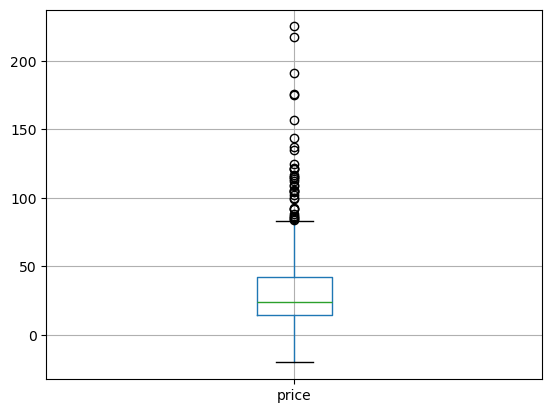

In [42]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_merge.boxplot(column='price')

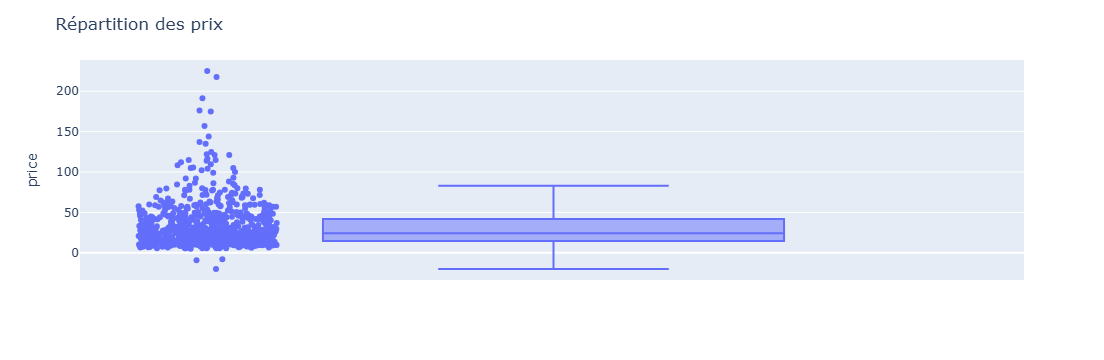

In [43]:
#Autre méthode avec plotly express
fig = px.box(df_merge, y="price", points="all")
fig.update_layout(title="Répartition des prix")
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [44]:
#Calculer la moyenne du prix
mean = df_merge['price'].mean(axis=0, skipna=True, numeric_only=True)
print(mean)
#Calculer l'écart-type du prix
#mesure la dispersion d'un jeu de données par rapport à sa moyenne

ecart_type = df_merge['price'].std()
print(ecart_type)

#Calculer le Z-score
z_score = (df_merge['price'] - mean) / ecart_type
print(z_score)

32.187696969696965
26.712076775505285
0     -0.299029
1      0.079077
2     -0.426313
3     -0.677136
4      0.517081
         ...   
820    0.479645
821    0.479645
822    0.846520
823   -0.212926
824   -0.594776
Name: price, Length: 825, dtype: float64


In [45]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
seuil = mean + 3 * ecart_type
print("Seuil prix (z > 3) :", seuil)

z_score_column = df_merge[z_score > 3][['product_id', 'price']]

z_score_column['z_score'] = z_score[z_score > 3].values

print(z_score_column)

Seuil prix (z > 3) : 112.32392729621282
     product_id  price   z_score
208        4352  225.0  7.218170
227        4402  176.0  5.383793
230        4406  157.0  4.672505
242        4594  144.0  4.185833
411        4904  137.0  3.923780
460        5001  217.5  6.937398
556        5612  124.8  3.467057
598        5767  175.0  5.346357
635        5892  191.3  5.956568
651        5917  122.0  3.362236
652        5918  114.0  3.062746
697        6126  135.0  3.848907
703        6202  116.4  3.152593
708        6212  115.0  3.100182
709        6213  121.0  3.324800
711        6215  115.0  3.100182
712        6216  121.0  3.324800


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [46]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
df_merge['price'].describe()

count    825.000000
mean      32.187697
std       26.712077
min      -20.000000
25%       14.500000
50%       24.300000
75%       42.000000
max      225.000000
Name: price, dtype: float64

In [47]:
#Définir un seuil pour les articles "outliers" en prix
#Q3 - Q1 = IQR
iqr = 42 - 14.5
print("IQR :", iqr)

#Seuil haut = Q3 + 1.5 * IQR
outliers = (42 + 1.5*iqr)
print("Outliers :", outliers)

IQR : 27.5
Outliers : 83.25


In [48]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
sum = ((df_merge['price'] > outliers) | (df_merge['price'] < 0)).sum()
print("Nombre d'articles", sum)
print(df_merge['price'].count())
proportion = ((sum / df_merge['price'].count()) * 100).round(2)
print("Proportion de l'ensemble du catalogue outliers :", proportion, '%')

Nombre d'articles 39
825
Proportion de l'ensemble du catalogue outliers : 4.73 %


In [49]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?

#Les prix supérieurs à 83.25€ ont tout à fait lieu d'être, car ils peuvent représenter une bouteille "luxe" avec peu de stock et beaucoup de demande.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [50]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
df_merge['ca_par_article'] = df_merge['price'] * df_merge['total_sales']

#Calculer la somme de la colonne "ca_par_article"
#Ce résultat correspond au chiffre d'affaire du site web
ca_total = df_merge['ca_par_article'].sum()
print(ca_total)

143680.1


In [51]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_merge = df_merge.sort_values(by="ca_par_article", ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_merge = df_merge.reset_index(drop=True)
#Afficher les 20 premiers articles en CA
top20 = df_merge.head(20)
print(top20)
#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(
    top20,
    x="post_title",
    y="ca_par_article",
    title="Top 20 des articles par chiffre d'affaires",
    labels={"post_title": "Article", "ca_par_article": "Chiffre d'affaires"}
)

fig.show()

    product_id  onsale_web  price  stock_quantity stock_status  \
0         4352           1  225.0               0   outofstock   
1         5892           1  191.3              98      instock   
2         4353           1   79.5             127      instock   
3         5826           1   41.2              34      instock   
4         6212           1  115.0              16      instock   
5         5026           1   86.8             101      instock   
6         5008           1  105.0              12      instock   
7         5767           1  175.0              12      instock   
8         6126           1  135.0             138      instock   
9         5025           1  112.0             136      instock   
10        6201           1  105.6              16      instock   
11        4406           1  157.0              12      instock   
12        4647           1   28.5              45      instock   
13        4358           1   77.0              81      instock   
14        

In [52]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_merge['part_ca'] = df_merge['ca_par_article'] / df_merge['ca_par_article'].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_merge['part_ca_cumulee'] = df_merge['part_ca'].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
nb_articles_80 = (df_merge['part_ca_cumulee'] <= 0.8).sum()
print('Articles représentant 80% du CA:', nb_articles_80)
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion = nb_articles_80 / len(df_merge) * 100
print('Part du CA :', proportion.round(2), '%')

Articles représentant 80% du CA: 434
Part du CA : 52.61 %


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

    product_id  onsale_web  price  stock_quantity stock_status  \
0         4867           1    9.9             121      instock   
1         4203           1    9.9              74      instock   
2         4275           1   14.9              62      instock   
3         4726           1   12.7               0   outofstock   
4         4647           1   28.5              45      instock   
5         5826           1   41.2              34      instock   
6         6129           1    5.2              68      instock   
7         4220           1   11.6              48      instock   
8         5803           1   17.1              47      instock   
9         6569           1   29.0              58      instock   
10        5778           1    5.8              44      instock   
11        5695           1    6.5              33      instock   
12        5777           1    5.7              51      instock   
13        4059           1    8.7              34      instock   
14        

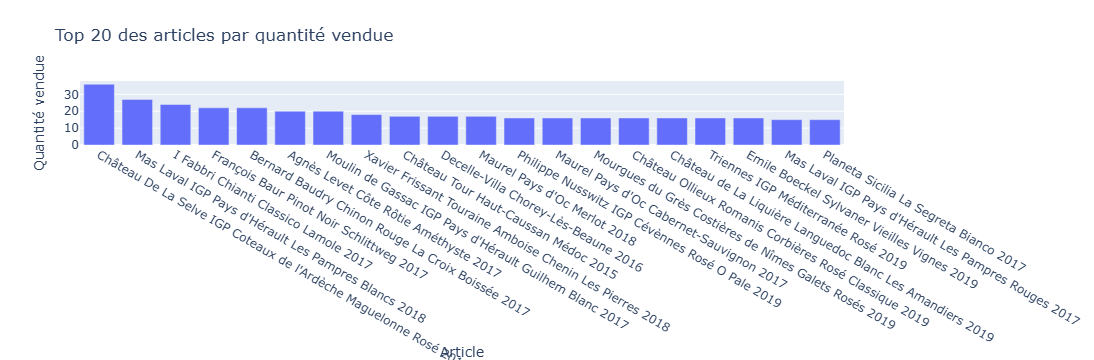

In [53]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_merge = df_merge.sort_values(by="total_sales", ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_merge = df_merge.reset_index(drop=True)
#Afficher les 20 premiers articles en quantité
top20_qt = df_merge.head(20)
print(top20_qt)
#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(
    top20_qt,
    x="post_title",
    y="total_sales",
    title="Top 20 des articles par quantité vendue",
    labels={"post_title": "Article", "total_sales": "Quantité vendue"}
)

fig.show()

In [54]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
df_merge['part_quantite'] = df_merge['total_sales'] / df_merge['total_sales'].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_merge['part_quantite_cumulee'] = df_merge['part_quantite'].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
nb_articles_80_qt = (df_merge['part_quantite_cumulee'] <= 0.8).sum()
print(nb_articles_80_qt)
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion = nb_articles_80_qt / len(df_merge) * 100
print(proportion.round(2), '%')

433
52.48 %


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [55]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Import de numpy 
import numpy as np
#Création de la colonne Rotation de stock
df_merge['rotation_stock'] = df_merge['stock_quantity'] / (df_merge['total_sales'] / 12)
#Remplacement des "inf" par 0
df_merge['rotation_stock'] = df_merge['rotation_stock'].replace([np.inf, -np.inf], 0)
#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_sorted_stock = df_merge.sort_values(by='rotation_stock', ascending=False)
#Graphique en barre du flop 20 des produits qui ont le plus de mois de stock
flop20 = df_sorted_stock.head(20)
import plotly.express as px

fig = px.bar(
    flop20,
    x='post_title',
    y='rotation_stock',
    title="Flop 20 - Produits avec le plus de mois de stock",
    labels={"post_title": "Produit", "rotation_stock": "Mois de stock"}
)

fig.show()

In [56]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros - avec le prix d'achat
df_merge['valorisation_stock_euros'] = df_merge['stock_quantity'] * df_merge['purchase_price']
#Calculer la somme de la colonne "Valorisation_stock_euros"
valorisation_totale = df_merge['valorisation_stock_euros'].sum()
print(valorisation_totale, '€')

298555.76 €


In [57]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
total_stock = df_merge['stock_quantity'].sum()
print(total_stock)

17811


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [58]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
df_merge['prix_ht'] = df_merge['price'] / 1.2
#Création de la colonne Taux de marge
df_merge['taux_marge'] = (df_merge['prix_ht'] - df_merge['purchase_price']) / df_merge['prix_ht']
#Afficher le prix minimum de la colonne "taux_marge"
taux_min = df_merge['taux_marge'].min()
print('Taux minimum :', taux_min)
#Afficher le prix maximum de la colonne "taux_marge"
taux_max = df_merge['taux_marge'].max()
print("Taux maximum :", taux_max)

print(df_merge['taux_marge'])

Taux minimum : -6.3498814229249
Taux maximum : 1.651
0      0.410909
1      0.392727
2      0.373423
3      0.355591
4      0.404632
         ...   
820    0.398452
821    0.379871
822    0.373867
823    0.355200
824    0.392302
Name: taux_marge, Length: 825, dtype: float64


In [59]:
############################
# Analyse du taux de marge #
############################

#Suppression des prix négatifs
df_merge = df_merge[df_merge['price'] >= 0]

#Afficher le prix minimum de la colonne "taux_marge"
taux_min = df_merge['taux_marge'].min()
print('Taux minimum :', taux_min)
#Afficher le prix maximum de la colonne "taux_marge"
taux_max = df_merge['taux_marge'].max()
print("Taux maximum :", taux_max)

print(df_merge['taux_marge'])

Taux minimum : -6.3498814229249
Taux maximum : 0.477568
0      0.410909
1      0.392727
2      0.373423
3      0.355591
4      0.404632
         ...   
820    0.398452
821    0.379871
822    0.373867
823    0.355200
824    0.392302
Name: taux_marge, Length: 822, dtype: float64


In [60]:
#Affichage de la ligne avec un taux de marge inférieur à 0
df_perte = df_merge[df_merge['taux_marge'] < 0]
df_perte.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,_merge,total_sales,product_type,...,indicator,ca_par_article,part_ca,part_ca_cumulee,part_quantite,part_quantite_cumulee,rotation_stock,valorisation_stock_euros,prix_ht,taux_marge
697,4355,1,12.65,97,instock,77.48,12589,both,0.0,Champagne,...,both,0.0,0.0,1.0,0.0,1.0,0.0,7515.56,10.541667,-6.349881
741,4864,0,8.30,0,outofstock,9.99,15154,both,NaN,NaN,...,left_only,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.916667,-0.444337
769,6324,0,92.00,18,instock,99.00,NaN,both,NaN,NaN,...,both,NaN,NaN,NaN,NaN,NaN,NaN,1782.00,76.666667,-0.291304
819,7196,0,31.00,55,instock,31.20,NaN,both,NaN,NaN,...,both,NaN,NaN,NaN,NaN,NaN,NaN,1716.00,25.833333,-0.207742


In [61]:
#Création d'un dataframe avec les taux positifs
df_marge_positive = df_merge[df_merge['taux_marge'] > 0]
#Afficher le prix minimum de la colonne "taux_marge"
taux_min = df_marge_positive['taux_marge'].min()
print(taux_min)
#Afficher le prix maximum de la colonne "taux_marge"
taux_max = df_marge_positive['taux_marge'].max()
print(taux_max)

0.22778625954198473
0.477568


In [62]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_marge_par_type = df_merge.groupby('product_type')['taux_marge'].mean().reset_index()
df_marge_par_type = df_marge_par_type.sort_values(by='taux_marge', ascending=False)
#Affichage dans un graphique du taux de marge par type de produit
fig = px.bar(
    df_marge_par_type,
    x='product_type',
    y='taux_marge',
    title="Taux de marge moyen par type de produit",
    labels={"product_type": "Type de produit", "taux_marge": "Taux de marge moyen"}
)

fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

In [63]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn
import seaborn as sns

#Création d'une heatmap de corrélation avec les variables stock, sales et price
df_corr = df_merge[['stock_quantity', 'total_sales', 'price']]
correlation = df_corr.corr()
fig = px.imshow(
    correlation,
    text_auto=True,
    title="Heatmap des corrélations"
)

fig.show()

In [64]:
#Que peut-on conclure des corrélations ?
#(+0.44) - total_sales et stock_quantity
#Plus un produit se vend, plus il y a de stock.

#-(0.09) - price et stock_quantity
#Le prix n’a pas vraiment de lien avec la quantité en stock.

#(+0.52) - price et total_sales
#Plus le prix augmente, moins le produit se vend.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [65]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
df_merge.to_excel("df_total_export.xlsx", index=False)